# lithovox-exports: voorbeelden

Dit notebook laat stap voor stap zien hoe je met het Python-pakket **lithovox-exports** een LithoVox model (een `.nc`-bestand) gebruikt: visualiseren, doorsneden maken en exporteren naar je eigen software.

**Wat is het model?** LithoVox levert de ondergrond langs een dijk, kade of tracé als een *voxelmodel*: een 3D-raster van blokjes (voxels), elk met één grondsoort. Het raster volgt een **referentielijn** (bijvoorbeeld de kruin van een dijk) en heeft drie richtingen:

| as | betekenis | in het bestand |
|---|---|---|
| **s** | *metrering*: meters langs de referentielijn, vanaf het eerste punt | `s` |
| **d** | *afstand tot de referentielijn*, haaks erop; **negatief = buitenwaarts** (bijvoorbeeld de waterkant), **positief = binnenwaarts** (de polderkant) | `d` |
| **z** | *hoogte* | `z` |

Een **dwarsdoorsnede** is een uitsnede van het model haaks op de referentielijn bij één metrering, precies wat rekenprogramma's als D-Stability nodig hebben.

**Wat kun je ermee?**

| export | voor | methode |
|---|---|---|
| D-Stability (`.stix`) | stabiliteit, met je eigen grondparameters | `CrossSection.to_dstability` |
| D-Geo Flow (`.flox`) | grondwaterstroming / piping | `CrossSection.to_dgeoflow` |
| XSLOPE (`.xlsx` / `.zip`) | stabiliteit in XSLOPE | `CrossSection.to_xslope` |
| DXF (`.dxf`) | GEO5, AutoCAD en andere CAD | `CrossSection.to_dxf` |
| CSV (`.csv`) | eigen scripts, Excel | `CrossSection.to_csv` |
| GLB (`.glb`) | 3D-viewers, Blender | `Model.to_glb` |
| 3D Tiles (`.zip`) | Cesium, ArcGIS, QGIS | `Model.to_tiles` |
| LAZ (`.laz`) | puntenwolk in QGIS, ArcGIS | `Model.to_laz` |

Daarnaast maakt het pakket figuren (kaart, doorsnede, grondkolom) en geeft het de grondopbouw op elk punt als een virtuele boring.

## 1. Installatie

Het pakket heeft Python 3.12 of nieuwer nodig. Installeer het met pip:

```
pip install lithovox-exports
```

of, in een project dat met [uv](https://docs.astral.sh/uv/) werkt:

```
uv add lithovox-exports
```

Alle benodigde pakketten (d-geolib voor D-Stability en D-Geo Flow, ezdxf, laspy, matplotlib, ...) worden automatisch meegeïnstalleerd. Wil je dit notebook zelf draaien, installeer dan ook Jupyter (`pip install jupyterlab`).

## 2. Het model openen

Je opent een model met `Model("pad/naar/model.nc")`. Het bestand wordt daarbij **niet** helemaal ingelezen: alleen de beschrijving (grid, grondsoorten, coördinatenstelsel). De voxels zelf worden pas gelezen als je een doorsnede of export vraagt, en dan alleen het stuk dat nodig is. Ook modellen van vele gigabytes openen dus direct.

Pas `MODEL_PAD` hieronder aan naar je eigen bestand. Alle bestanden die dit notebook maakt, komen in de map `UITVOER`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from lithovox_exports import Model

# Pas dit pad aan naar je eigen corridormodel.
MODEL_PAD = Path(r"C:\Users\brein\Documents\Temp\hhnk_andijk.nc")
# Hier komen alle bestanden die dit notebook maakt.
UITVOER = Path("uitvoer")
UITVOER.mkdir(exist_ok=True)

model = Model(MODEL_PAD)
model

Model('hhnk_andijk', 'reflijn_kruin', 1741 m, 14 grondsoorten)

Is het bestand geen LithoVox model, dan geeft `Model(...)` een `ValueError` met de melding *"Dit bestand is geen LithoVox-corridormodel"*.

## 3. Eigenschappen van het model

Het `Model`-object vertelt je wat er in het bestand staat. Alle lengtes zijn in meters.

In [2]:
ds, dd, dz = model.voxel_size
buiten, binnen = model.offsets
onder, boven = model.heights

print(f"project              {model.project}")
print(f"referentielijn       {model.name}")
print(f"gemaakt op           {model.created}")
print(f"lengte van de lijn   {model.length:.1f} m")
print(f"breedte              {buiten:g} m (buitenwaarts) tot {binnen:g} m (binnenwaarts)")
print(f"hoogte van het grid  {onder:g} tot {boven:g} m")
print(f"aantal voxels        {model.shape[0]} x {model.shape[1]} x {model.shape[2]} (s x d x z)")
print(f"voxelgrootte         {ds:g} m langs, {dd:g} m dwars, {dz:g} m hoog")
print(f"coördinatenstelsel   {model.crs}")
print(f"verticaal datum      {model.vertical_datum or 'onbekend'}")

project              hhnk_andijk
referentielijn       reflijn_kruin
gemaakt op           2026-10-22T08:01:56+00:00
lengte van de lijn   1741.2 m
breedte              -30 m (buitenwaarts) tot 70 m (binnenwaarts)
hoogte van het grid  -18.2 tot 10.6 m
aantal voxels        3483 x 1000 x 288 (s x d x z)
voxelgrootte         0.5 m langs, 0.1 m dwars, 0.1 m hoog
coördinatenstelsel   EPSG:28992
verticaal datum      onbekend


Een paar dingen om op te letten:

- **Coördinatenstelsel.** Elk model heeft zijn eigen coördinatenstelsel (`model.crs`), bijvoorbeeld `EPSG:28992` (RD New) in Nederland, maar het kan ook een ander stelsel zijn. Alle x, y-coördinaten die het pakket geeft, zijn in dat stelsel.
- **Verticaal datum.** Als het model weet ten opzichte waarvan de hoogtes gelden (bijvoorbeeld NAP), staat dat in `model.vertical_datum`. In dit model is het onbekend (`None`): de hoogtes komen dan direct uit de hoogtedata waarmee het model gemaakt is. Figuren tonen de hoogte dan als "m" in plaats van "m NAP".
- **Grid en grond.** Het grid is een rechthoekig blok; boven het maaiveld zijn de voxels leeg. De grond zelf begint dus op verschillende hoogtes.

### Grondsoorten en kleuren

`model.soils` geeft de grondsoorten in de volgorde van hun code in het bestand (code 0 is de eerste), `model.colors` hun kleur. Exports en figuren gebruiken dezelfde kleuren als de LithoVox-viewer.

In [3]:
for code, naam in enumerate(model.soils):
    print(f"{code:2d}  {naam:28s} {model.colors.get(naam, '-')}")

 0  basalton                     #b9b6b6
 1  basisveen                    #a87038
 2  hollandveen                  #c7ab8e
 3  jonge_zeeklei_na             #ace86f
 4  jonge_zeeklei_zandig_na      #ace86f
 5  klei_antropogeen             #b9d4b4
 6  lz_antropogeen               #e972d6
 7  oude_zeeklei_licht_na        #90b94d
 8  stortsteen                   #3e3e3e
 9  zand_antropogeen             #ffffb8
10  zand_bx                      #fae2b7
11  zand_eem                     #f1b198
12  zand_kleiig_na               #f1f5c7
13  zand_na                      #f1f5c7


## 4. Kaart van het model

`model.plot_map()` tekent het model van bovenaf:

- de **omtrek** van het model (grijs),
- de **referentielijn** (zwart) met metreringen; de getallen staan aan de buitenwaartse kant,
- het **maaiveld** in kleur (zet dit uit met `ground=False`),
- met `chainages=[...]` de plekken van dwarsdoorsneden (rood).

De afstand tussen de metreringslabels kies je met `step=` (standaard een rond getal dat bij de lengte past). Net als alle tekenfuncties in dit pakket geeft `plot_map` een matplotlib-`Axes` terug, die je verder kunt aanpassen of opslaan.

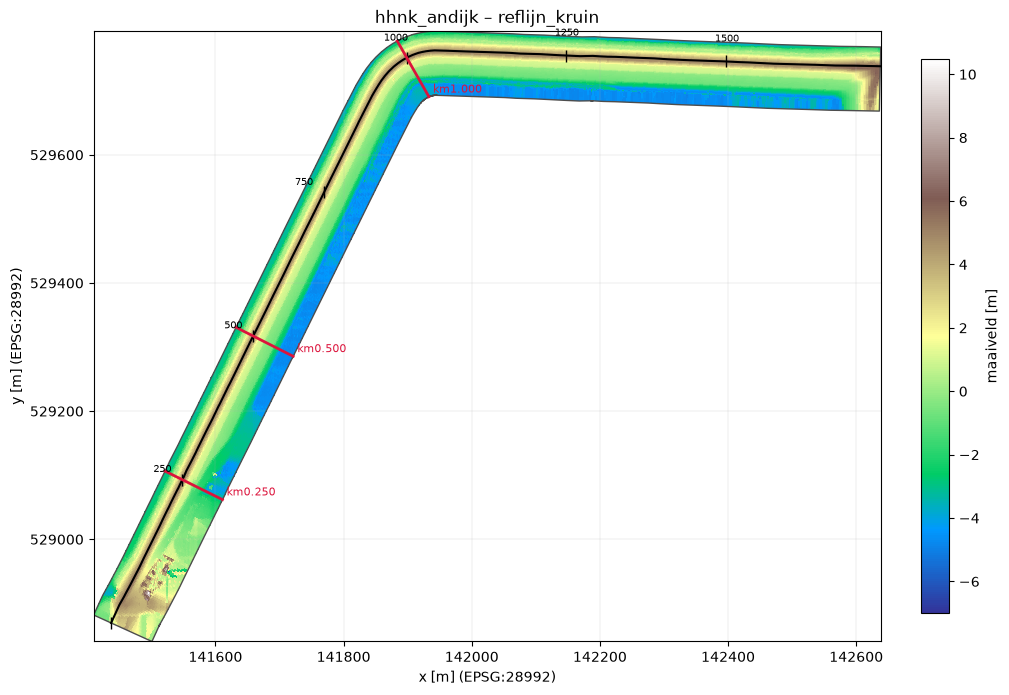

In [4]:
ax = model.plot_map(chainages=[250, 500, 1000])
ax.figure.savefig(UITVOER / "kaart.png", dpi=150)
plt.show()

## 5. Een dwarsdoorsnede

`model.cross_section(metrering)` maakt de dwarsdoorsnede bij de modelkolom die het dichtst bij de gevraagde metrering ligt. De voxels van die kolom worden omgezet naar **grondpolygonen**:

1. kleine spikkels (gebiedjes van minder dan 6 voxels) krijgen de grondsoort van hun buren;
2. de grenzen tussen grondsoorten worden opgespoord langs de randen van de voxels;
3. die grenzen worden gladgemaakt (zie hoofdstuk 6);
4. lenzen worden "losgeknipt", zodat geen polygoon een gat heeft (D-Stability staat geen gaten in de geometrie toe).

Buurpolygonen delen hun punten precies, dus er zijn geen kieren of overlappingen.

In [ ]:
doorsnede = model.cross_section(500)

print("label               ", doorsnede.label)
print("gevraagde metrering ", doorsnede.chainage, "m")
print("gebruikte kolom     ", doorsnede.slice.chainage, "m")
print("aantal polygonen    ", len(doorsnede.polygons))
print("grondsoorten        ", ", ".join(doorsnede.soils))
print("begin A (buiten)    ", tuple(round(v, 2) for v in doorsnede.start))
print("eind B (binnen)     ", tuple(round(v, 2) for v in doorsnede.end))

label                km0.500
gevraagde metrering 500 m
gebruikte kolom      499.75 m
aantal polygonen     14
grondsoorten         basalton, basisveen, hollandveen, jonge_zeeklei_na, klei_antropogeen, lz_antropogeen, oude_zeeklei_licht_na, stortsteen, zand_antropogeen, zand_bx, zand_na
begin A (buiten)     (141632.11, 529330.75)
eind B (binnen)      (141721.33, 529285.6)


- `label` is de naam die de doorsnede in D-Stability en D-Geo Flow krijgt (en handig als bestandsnaam): `km0.500` betekent metrering 500 m.
- De gebruikte kolom kan iets afwijken van de gevraagde metrering: het model heeft een kolom om de `ds` meter (hier 0,5 m), en de doorsnede ligt in het midden van een kolom.
- `start` en `end` zijn de wereldcoördinaten (x, y in het stelsel van het model) van de uiteinden van de doorsnede: handig om de doorsnede op een kaart te zetten.

`doorsnede.plot()` tekent de doorsnede. De stippellijn is het maaiveld uit de hoogtedata waarmee het model gemaakt is.

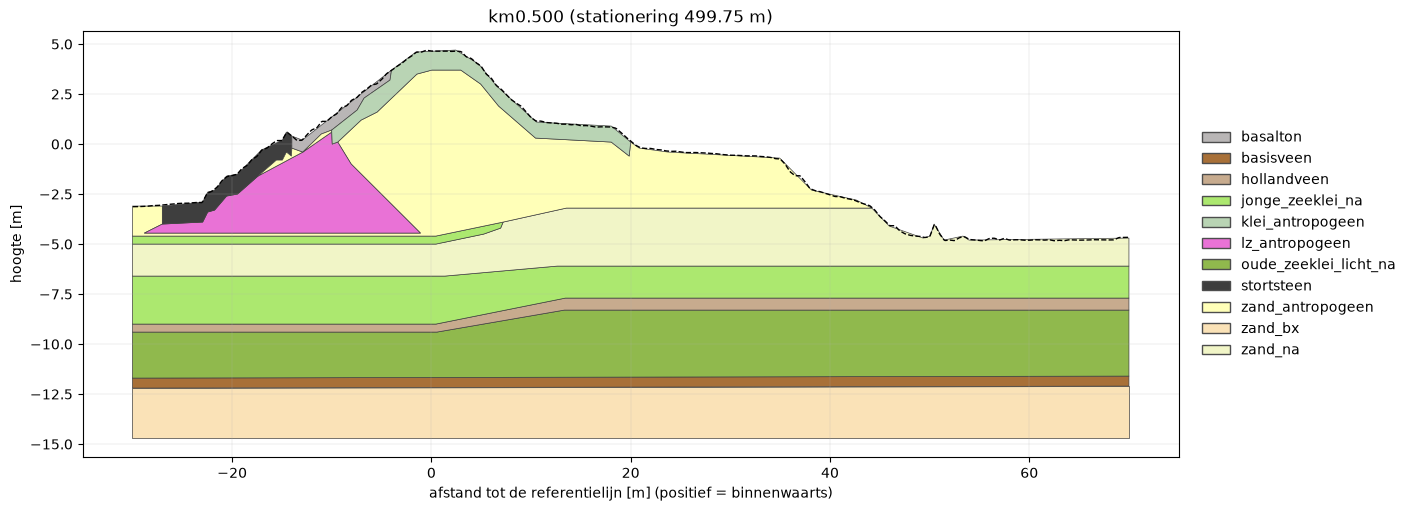

In [6]:
ax = doorsnede.plot()
ax.figure.savefig(UITVOER / f"{doorsnede.label}.png", dpi=150)
plt.show()

## 6. Gladmaken van de grenzen

De voxels geven trapvormige profielen. Standaard worden de grenzen gladgemaakt met `smoothing=1.5`: een grens mag dan hooguit 1,5 voxel van de trap afliggen. Met `smoothing=0` houd je de trap van de voxels precies; met een grotere waarde krijg je rechtere lijnen en minder punten (eenvoudiger rekenmodellen), maar wijk je meer van het model af.

Hieronder dezelfde doorsnede drie keer, ingezoomd op het buitentalud.

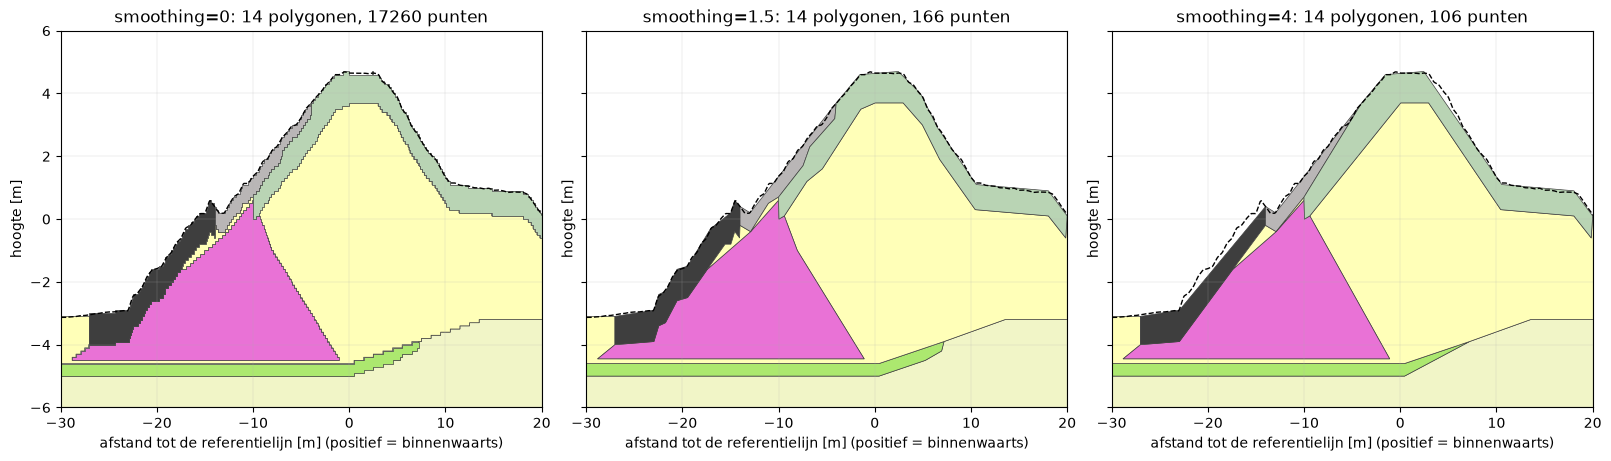

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True, layout="constrained")
for ax, smoothing in zip(axes, [0, 1.5, 4]):
    d = model.cross_section(500, smoothing=smoothing)
    punten = sum(len(p.points) for p in d.polygons)
    d.plot(ax=ax, legend=False)
    ax.set_title(f"smoothing={smoothing}: {len(d.polygons)} polygonen, {punten} punten")
    ax.set_xlim(-30, 20)
    ax.set_ylim(-6, 6)
plt.show()

## 7. De polygonen zelf (en CSV)

Wil je zelf iets met de geometrie doen, dan staan de polygonen in `doorsnede.polygons`. Elke `SoilPolygon` heeft:

- `soil`: de code van de grondsoort (een index in `model.soils`),
- `points`: de hoekpunten als `(x, z)`, tegen de klok in, niet gesloten (het eerste punt wordt niet herhaald). x is de afstand tot de referentielijn, z de hoogte.

In [8]:
eerste = doorsnede.polygons[0]
print("grondsoort:", model.soils[eerste.soil])
print("aantal punten:", len(eerste.points))
print("eerste punten:", [(round(x, 2), round(z, 2)) for x, z in eerste.points[:4]])

grondsoort: zand_bx
aantal punten: 4
eerste punten: [(-30.0, -12.2), (-30.0, -14.7), (70.0, -14.7), (70.0, -12.1)]


`to_csv` schrijft alle hoekpunten naar een CSV-bestand, een regel per punt, met de kolommen `polygoon`, `grondsoort`, `punt`, `x` en `z`. Het scheidingsteken is een komma en het decimaalteken een punt (de internationale standaard; in een (Nederlandse) Excel open je het via *Gegevens > Uit tekst/CSV*).

In [9]:
pad = doorsnede.to_csv(UITVOER / f"{doorsnede.label}.csv")
print(pad)
print("".join(pad.read_text(encoding="utf-8").splitlines(keepends=True)[:6]))

uitvoer\km0.500.csv
polygoon,grondsoort,punt,x,z
0,zand_bx,0,-30.0,-12.2
0,zand_bx,1,-30.0,-14.7
0,zand_bx,2,70.0,-14.7
0,zand_bx,3,70.0,-12.1
1,basisveen,0,70.0,-12.1



## 8. D-Stability

### 8.1 Alleen de geometrie

`to_dstability` schrijft een D-Stability-bestand (`.stix`) met de grondpolygonen als lagen. Elke grondsoort uit het model wordt een grondsoort in D-Stability met dezelfde naam en kleur, maar met de **standaardparameters** van D-Stability. Waterspanningen, belastingen en de rekeninstellingen vul je daarna zelf in D-Stability in.

In [10]:
pad = doorsnede.to_dstability(UITVOER / f"{doorsnede.label}.stix")
print(pad, f"({pad.stat().st_size / 1000:.0f} kB)")

uitvoer\km0.500.stix (7 kB)


### 8.2 Met je eigen grondsoorten en parameters

Meestal heb je al een **grondsoortenbibliotheek**: een D-Stability-bestand met je eigen grondsoorten en hun parameters (volumegewicht, sterkte, ...). Geef dat bestand mee met `soils=` en alle grondsoorten uit dat bestand gaan, met hun parameters, het nieuwe bestand in. Elke grondsoort uit het model wordt daarna gekoppeld aan een grondsoort uit de bibliotheek:

1. heb je in `mapping` voor de modelgrondsoort een code opgegeven, dan wordt dat de grondsoort (`None` betekent: niet koppelen, de modelgrondsoort blijft dan een losse grondsoort met standaardparameters);
2. anders wordt de bibliotheekgrondsoort genomen met **dezelfde code of naam**, waarbij hoofdletters, spaties, `_` en `-` niet uitmaken (`"Zand antropogeen"` = `"zand_antropogeen"`);
3. vindt het pakket niets, dan blijft de modelgrondsoort een lege grondsoort.

Noem je in `mapping` een code die niet in de bibliotheek staat, dan krijg je een `ValueError`, zodat een tikfout niet ongemerkt blijft.

Voor dit voorbeeld maken we eerst met d-geolib een kleine bibliotheek met drie grondsoorten en (fictieve) parameters. In de praktijk gebruik je bij voorkeur je eigen `.stix`-bestand.

In [11]:
from geolib.models.dstability import DStabilityModel
from geolib.soils.soil import MohrCoulombParameters, ShearStrengthModelTypePhreaticLevel, Soil, SoilWeightParameters

MOHR_COULOMB = ShearStrengthModelTypePhreaticLevel.MOHR_COULOMB


def grondsoort(naam, code, droog, nat, c, phi):
    # Een D-Stability-grondsoort met volumegewichten (kN/m3) en Mohr-Coulomb (c in kPa, phi in graden).
    return Soil(
        name=naam,
        code=code,
        soil_weight_parameters=SoilWeightParameters(unsaturated_weight=droog, saturated_weight=nat),
        mohr_coulomb_parameters=MohrCoulombParameters(cohesion=c, friction_angle=phi),
        shear_strength_model_above_phreatic_level=MOHR_COULOMB,
        shear_strength_model_below_phreatic_level=MOHR_COULOMB,
    )


bibliotheek = DStabilityModel()
# Zonder de standaardgrondsoorten van D-Stability: alleen onze eigen drie.
bibliotheek.datastructure.soils.Soils = []
bibliotheek.datastructure.soilvisualizations.SoilVisualizations = []
bibliotheek.add_soil(grondsoort("Klei", "KLEI", 15.0, 15.5, 5.0, 27.5))
bibliotheek.add_soil(grondsoort("Veen", "VEEN", 10.5, 10.5, 2.0, 20.0))
bibliotheek.add_soil(grondsoort("Zand", "ZAND", 18.0, 20.0, 0.0, 32.5))
BIBLIOTHEEK = UITVOER / "grondsoorten.stix"
bibliotheek.serialize(BIBLIOTHEEK)
print(BIBLIOTHEEK)

uitvoer\grondsoorten.stix


De namen in het model (`jonge_zeeklei_na`, `hollandveen`, ...) komen niet overeen met de codes in de bibliotheek (`KLEI`, `VEEN`, `ZAND`), dus maken we een `mapping`. Je kunt die met de hand uitschrijven, maar met een paar regels Python gaat het ook automatisch. Hier zoeken we de woorden "veen", "klei" en "zand" in de naam; staan er meer in, dan bepaalt het woord dat **het eerst** staat de code, want de hoofdnaam staat vooraan (`zand_kleiig_na` is zand, `jonge_zeeklei_zandig_na` is klei). Grondsoorten zonder een van die woorden (basalton, stortsteen, ...) koppelen we niet (`None`).

In [ ]:
WOORDEN = {"veen": "VEEN", "klei": "KLEI", "zand": "ZAND"}


def kies_code(naam):
    # De plek van elk woord in de naam; het woord dat het eerst gevonden wordt, wint.
    gevonden = [(naam.find(woord), code) for woord, code in WOORDEN.items() if woord in naam]
    return min(gevonden)[1] if gevonden else None


mapping = {naam: kies_code(naam) for naam in model.soils}
for naam, code in mapping.items():
    print(f"{naam:28s} -> {code}")

basalton                     -> None
basisveen                    -> VEEN
hollandveen                  -> VEEN
jonge_zeeklei_na             -> KLEI
jonge_zeeklei_zandig_na      -> KLEI
klei_antropogeen             -> KLEI
lz_antropogeen               -> None
oude_zeeklei_licht_na        -> KLEI
stortsteen                   -> None
zand_antropogeen             -> ZAND
zand_bx                      -> ZAND
zand_eem                     -> ZAND
zand_kleiig_na               -> ZAND
zand_na                      -> ZAND


Controleer zo'n automatische koppeling altijd. `lz_antropogeen` bevat bijvoorbeeld geen van de drie woorden en blijft ongekoppeld. Weet je dat het een zandsoort is, pas `mapping` dan met de hand aan:

In [13]:
mapping["lz_antropogeen"] = "ZAND"

pad = doorsnede.to_dstability(UITVOER / f"{doorsnede.label}_met_parameters.stix", soils=BIBLIOTHEEK, mapping=mapping)
print(pad)

uitvoer\km0.500_met_parameters.stix


Ter controle lezen we het bestand terug met d-geolib en tellen we per grondsoort het aantal lagen:

In [14]:
from collections import Counter

stix = DStabilityModel()
stix.parse(pad)
code_van = {s.Id: s.Code for s in stix.datastructure.soils.Soils}
lagen = Counter(code_van[laag.SoilId] for laag in stix.datastructure.soillayers[0].SoilLayers)
for code, aantal in sorted(lagen.items()):
    print(f"{code:12s} {aantal} lagen")

KLEI         4 lagen
VEEN         2 lagen
ZAND         6 lagen
basalton     1 lagen
stortsteen   1 lagen


## 9. D-Geo Flow

`to_dgeoflow` schrijft een D-Geo Flow-bestand (`.flox`) met dezelfde lagen en grondsoorten (naam en kleur; de doorlatendheden zijn de standaardwaarden van D-Geo Flow). Randvoorwaarden (waterstanden), het mesh en de rekeninstellingen vul je zelf in.

In [15]:
pad = doorsnede.to_dgeoflow(UITVOER / f"{doorsnede.label}.flox")
print(pad)

uitvoer\km0.500.flox


## 10. XSLOPE

`to_xslope` schrijft een invoerbestand voor [XSLOPE](https://github.com/njones61/xslope), gebaseerd op het officiële lege sjabloon van XSLOPE. De kleuren van de grondsoorten staan in een apart bestand `<naam>_styles.json`, dat XSLOPE Studio naast het werkboek verwacht. Daarom zijn er twee vormen:

- een pad dat eindigt op **`.zip`**: het werkboek en de stijlen samen in één zip (handig om te versturen; pak beide samen uit);
- een pad dat eindigt op **`.xlsx`**: het werkboek, met `<naam>_styles.json` ernaast.

Ook hier kun je `soils=` en `mapping=` meegeven. De materialen krijgen dan het droge en natte volumegewicht en, bij Mohr-Coulomb, c en phi uit de bibliotheek (XSLOPE kent één sterkte per materiaal: die van onder de freatische lijn). Modelgrondsoorten die aan dezelfde bibliotheekgrondsoort gekoppeld zijn, worden één materiaal.

In [16]:
zip_pad = doorsnede.to_xslope(UITVOER / f"{doorsnede.label}_xslope.zip", soils=BIBLIOTHEEK, mapping=mapping)
xlsx_pad = doorsnede.to_xslope(UITVOER / f"{doorsnede.label}_xslope.xlsx")
print(zip_pad)
print(xlsx_pad, "en", xlsx_pad.with_name(f"{xlsx_pad.stem}_styles.json").name)

uitvoer\km0.500_xslope.zip
uitvoer\km0.500_xslope.xlsx en km0.500_xslope_styles.json


## 11. DXF (GEO5, AutoCAD)

`to_dxf` schrijft een 2D-tekening (AutoCAD 2004-formaat) met drie soorten lagen:

| laag | inhoud | gebruik in GEO5 |
|---|---|---|
| `INTERFACES` | de grenzen tussen grondsoorten en het maaiveld, als open lijnen | *File > Import > DXF to interfaces* |
| `OUTLINE` | de zijkanten en onderkant van het model | |
| `SOIL_<naam>` | per grondsoort zijn vlakken, gesloten, in de kleur van de grondsoort | *DXF to template*, om te zien welk vlak welke grondsoort is |

x is de afstand tot de referentielijn, y de hoogte. De parameters van de grondsoorten vul je in het ontvangende programma in.

In [17]:
import ezdxf

pad = doorsnede.to_dxf(UITVOER / f"{doorsnede.label}.dxf")
tekening = ezdxf.readfile(pad)
per_laag = Counter(e.dxf.layer for e in tekening.modelspace())
for laag, aantal in sorted(per_laag.items()):
    print(f"{laag:32s} {aantal} polylijnen")

INTERFACES                       27 polylijnen
OUTLINE                          13 polylijnen
SOIL_basalton                    1 polylijnen
SOIL_basisveen                   1 polylijnen
SOIL_hollandveen                 1 polylijnen
SOIL_jonge_zeeklei_na            2 polylijnen
SOIL_klei_antropogeen            1 polylijnen
SOIL_lz_antropogeen              1 polylijnen
SOIL_oude_zeeklei_licht_na       1 polylijnen
SOIL_stortsteen                  1 polylijnen
SOIL_zand_antropogeen            3 polylijnen
SOIL_zand_bx                     1 polylijnen
SOIL_zand_na                     1 polylijnen


## 12. Een reeks doorsneden

`model.cross_sections(every=...)` geeft dwarsdoorsneden op vaste afstand, van `start` (standaard 0) tot en met `stop` (standaard het eind van de lijn). Ze worden een voor een gemaakt, dus ook een lange reeks past in het geheugen. Hier een D-Stability-bestand om de 250 m, met de bibliotheek van hierboven:

In [18]:
reeks = UITVOER / "reeks"
reeks.mkdir(exist_ok=True)
for d in model.cross_sections(every=250):
    pad = d.to_dstability(reeks / f"{d.label}.stix", soils=BIBLIOTHEEK, mapping=mapping)
    print(pad.name, "-", len(d.polygons), "lagen")

km0.000.stix - 9 lagen


km0.250.stix - 15 lagen


km0.500.stix - 14 lagen


km0.750.stix - 15 lagen
km1.000.stix - 16 lagen


km1.250.stix - 15 lagen
km1.500.stix - 20 lagen


En om een indruk te krijgen van hoe de ondergrond langs de lijn verandert, een paar doorsneden onder elkaar:

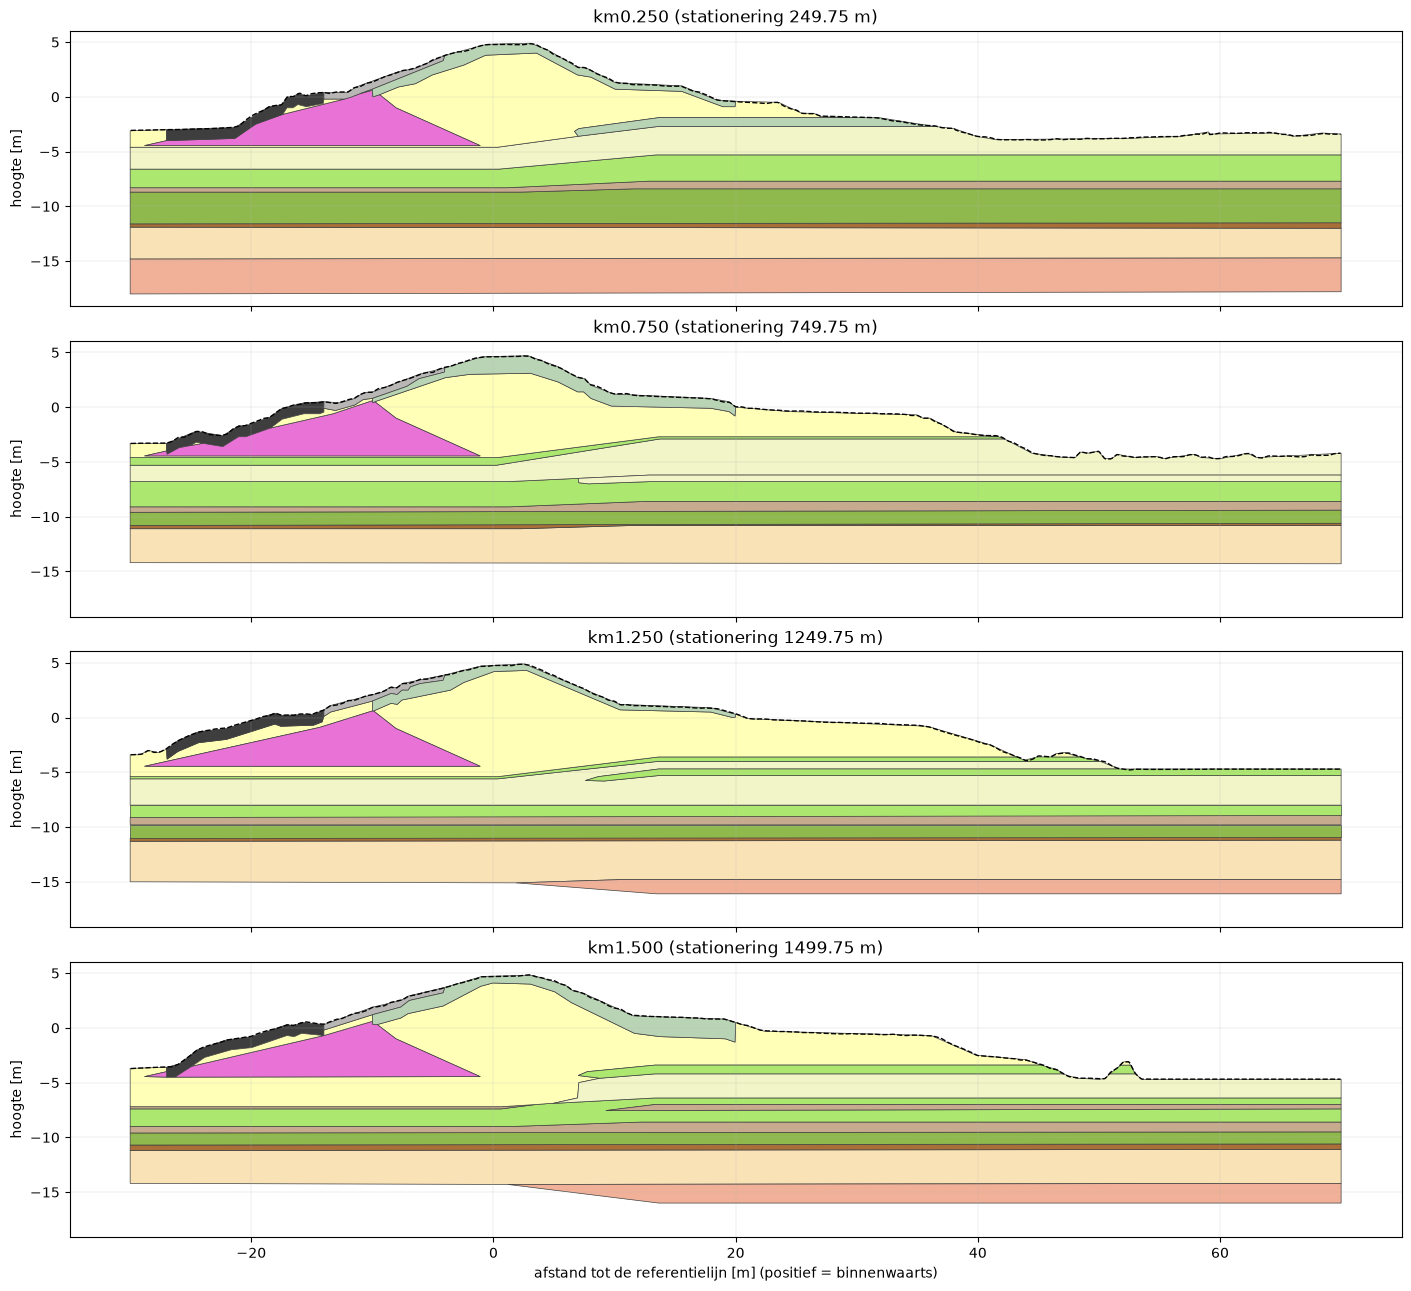

In [ ]:
metreringen = [250, 750, 1250, 1500]
fig, axes = plt.subplots(len(metreringen), 1, figsize=(14, 3.2 * len(metreringen)), sharex=True, sharey=True, layout="constrained")
for ax, s in zip(axes, metreringen):
    model.cross_section(s).plot(ax=ax, legend=False)
    ax.set_xlabel("")
axes[-1].set_xlabel("afstand tot de referentielijn [m] (positief = binnenwaarts)")
plt.show()

## 13. Grondopbouw op een punt (virtuele boring)

`model.soil_column(metrering, afstand)` geeft de grondopbouw van de dichtstbijzijnde voxelkolom, als lagen van boven naar beneden. Elke `SoilLayer` heeft `top`, `bottom`, `thickness` en `soil`. `ground` is het maaiveld uit de hoogtedata.

In [ ]:
kolom = model.soil_column(500, 10)
print(f"metrering {kolom.chainage} m, afstand {kolom.offset} m, x = {kolom.x:.2f}, y = {kolom.y:.2f}")
print(f"maaiveld {kolom.ground:.2f} m\n")
print(f"{'bovenkant':>10s} {'onderkant':>10s} {'dikte':>6s}  grondsoort")
for laag in kolom.layers:
    print(f"{laag.top:10.2f} {laag.bottom:10.2f} {laag.thickness:6.2f}  {laag.soil}")

metrering 499.75 m, afstand 10.05 m, x = 141667.84, y = 529312.67
maaiveld 1.31 m

 bovenkant  onderkant  dikte  grondsoort
      1.30       0.50   0.80  klei_antropogeen
      0.50      -3.60   4.10  zand_antropogeen
     -3.60      -6.20   2.60  zand_na
     -6.20      -8.10   1.90  jonge_zeeklei_na
     -8.10      -8.60   0.50  hollandveen
     -8.60     -11.60   3.00  oude_zeeklei_licht_na
    -11.60     -12.10   0.50  basisveen
    -12.10     -14.70   2.60  zand_bx


Heb je een locatie in wereldcoördinaten (bijvoorbeeld van een sondering of boring), gebruik dan `model.soil_column_at(x, y)`. `model.locate(x, y)` geeft alleen de metrering en afstand. Ligt het punt buiten het model, dan krijg je een `ValueError`.

In [21]:
x, y = 141660.0, 529300.0
print("metrering en afstand:", model.locate(x, y))

try:
    model.locate(0, 0)
except ValueError as fout:
    print("buiten het model:", fout)

metrering en afstand: (484.75, 8.75)
buiten het model: Het punt (0, 0) ligt buiten het model


`kolom.plot()` tekent een kolom. Geef `colors=model.colors` mee voor de kleuren van het model. Hier drie kolommen naast elkaar: in het buitentalud, op de kruin en in de polder.

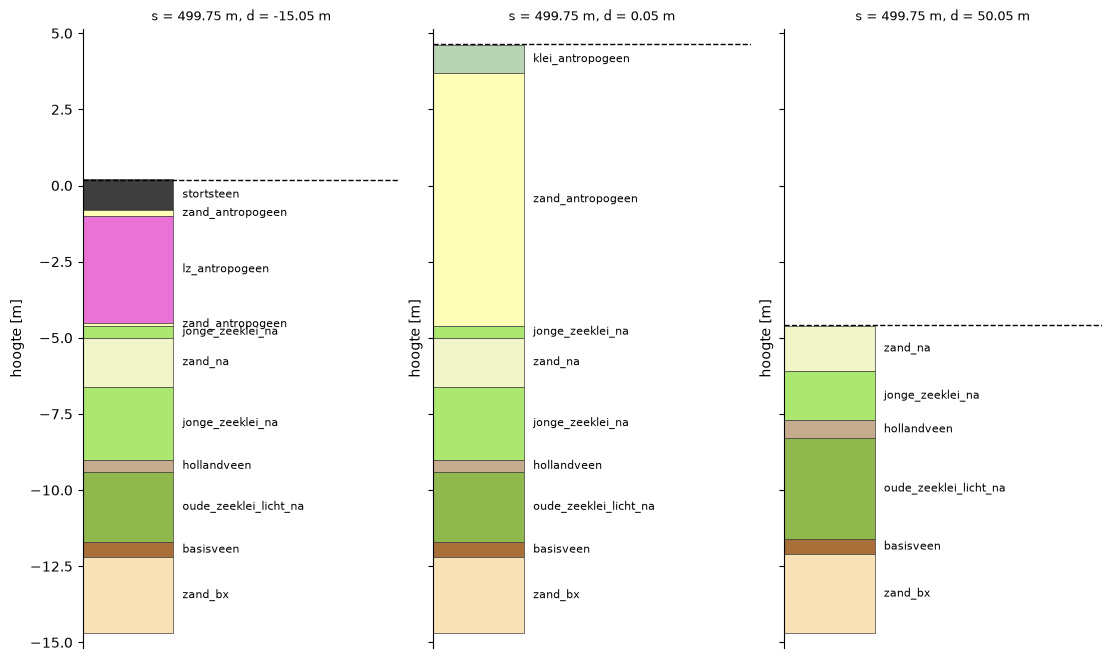

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5), sharey=True, layout="constrained")
for ax, afstand in zip(axes, [-15, 0, 50]):
    model.soil_column(500, afstand).plot(ax=ax, colors=model.colors)
plt.show()

## 14. Het hele model in 3D

Voor het hele model zijn er drie exports. Een model van fijne voxels (hier 0,1 x 0,1 m) zou daarin onhandelbaar groot worden, daarom worden de voxels eerst **grover gemaakt**: met `voxel_width` (dwars op de lijn) en `voxel_height` (omhoog) kies je de grootte van de weergavevoxels, standaard 1,0 x 0,2 m. Elke weergavevoxel krijgt de grondsoort die de meeste van zijn modelvoxels hebben. Langs de lijn blijft de lengte die van het model. Grotere voxels geven kleinere bestanden en zijn sneller.

Het model wordt in brokken gelezen, dus ook grote modellen passen in het geheugen. Reken voor een model als dit (1,7 km) op 10 tot 30 seconden per export.

### 14.1 GLB (3D-mesh)

Een GLB is een 3D-bestand dat veel viewers lezen (bijvoorbeeld Blender, Windows 3D Viewer of https://gltf-viewer.donmccurdy.com). Er staat één mesh per grondsoort in, in de kleur van de grondsoort, met alleen de buitenkant van het model.

De coördinaten zijn **lokaal**: in meters rond een oorsprong in het midden van het model (de getallen van wereldcoördinaten zijn te groot voor de nauwkeurigheid van glTF). De oorsprong staat in de `extras` van het bestand. Met `voxel_edges=True` worden de randen van elke voxel donkerder getekend (het bestand wordt dan ongeveer vier keer zo groot).

In [23]:
import json
import struct
import time

start = time.time()
pad = model.to_glb(UITVOER / "model.glb")
print(f"{pad} ({pad.stat().st_size / 1e6:.0f} MB, {time.time() - start:.0f} s)")

# De extras uit het JSON-deel van de GLB: daar staan de oorsprong, het coördinatenstelsel en de assen.
data = pad.read_bytes()
lengte = struct.unpack("<I", data[12:16])[0]
extras = json.loads(data[20 : 20 + lengte])["asset"]["extras"]
print(json.dumps({k: extras[k] for k in ["crs", "origin", "axes", "voxel"]}, indent=1))

uitvoer\model.glb (57 MB, 12 s)
{
 "crs": "EPSG:28992",
 "origin": [
  142024.0,
  529317.0,
  0.0
 ],
 "axes": {
  "x": "x - origin x",
  "y": "z (m)",
  "z": "-(y - origin y)"
 },
 "voxel": {
  "length": 0.5,
  "width": 1.0,
  "height": 0.2
 }
}


### 14.2 LAZ (puntenwolk)

`to_laz` schrijft een punt per weergavevoxel, in het coördinatenstelsel van het model, als gecomprimeerde LAS 1.4-puntenwolk. QGIS en ArcGIS lezen dat direct. De grondsoort zit in de **klasse** van het punt: klasse `64 + code` (de klassen 0 tot 63 hebben een vaste betekenis, zoals 2 = maaiveld). De code zelf staat ook in het veld *user data*.

In [24]:
import laspy
import numpy as np

start = time.time()
pad = model.to_laz(UITVOER / "model.laz", voxel_width=1.0, voxel_height=0.2)
print(f"{pad} ({pad.stat().st_size / 1e6:.0f} MB, {time.time() - start:.0f} s)")

wolk = laspy.read(pad)
print(f"{len(wolk.points):,} punten in {wolk.header.parse_crs().name}\n")
klassen, aantallen = np.unique(np.asarray(wolk.classification), return_counts=True)
for klasse, aantal in zip(klassen, aantallen):
    print(f"klasse {klasse}  {model.soils[klasse - 64]:28s} {aantal:>12,} punten")

uitvoer\model.laz (11 MB, 14 s)


26,331,499 punten in Amersfoort / RD New



klasse 64  basalton                           95,460 punten
klasse 65  basisveen                         905,050 punten
klasse 66  hollandveen                     1,413,910 punten
klasse 67  jonge_zeeklei_na                3,285,948 punten
klasse 68  jonge_zeeklei_zandig_na            35,148 punten
klasse 69  klei_antropogeen                  516,512 punten
klasse 70  lz_antropogeen                  1,132,136 punten
klasse 71  oude_zeeklei_licht_na           2,858,173 punten
klasse 72  stortsteen                        226,928 punten
klasse 73  zand_antropogeen                4,248,854 punten
klasse 74  zand_bx                         5,618,302 punten
klasse 75  zand_eem                        1,500,226 punten
klasse 76  zand_kleiig_na                    207,300 punten
klasse 77  zand_na                         4,287,552 punten


### 14.3 3D Tiles (Cesium, ArcGIS)

`to_tiles` schrijft het model als [OGC 3D Tiles](https://www.ogc.org/standard/3dtiles/) in een zip: `3d/tileset.json` en een tegel per 250 m van de lijn. De tegels staan op de juiste plek op de wereldbol, zodat je het model in Cesium, ArcGIS Pro of QGIS samen met luchtfoto's en andere lagen kunt bekijken. Standaard staan de randen van de voxels erin (`voxel_edges=True`).

**Over de hoogte:** 3D Tiles rekent met hoogtes boven de ellipsoïde. Heeft het model een bekend verticaal datum (zoals NAP, EPSG:7415), dan rekent het pakket de hoogtes om; daarvoor kan PROJ correctiegrids van internet (cdn.proj.org) downloaden. Is het datum onbekend, zoals in dit model, dan wordt de hoogte direct als ellipsoïdische hoogte genomen: het model ligt dan horizontaal goed, maar kan verticaal tientallen meters te hoog of te laag liggen (in Nederland ongeveer 40 m). In `tileset.json` staat dan `"accurate": false`.

In [25]:
import zipfile

start = time.time()
pad = model.to_tiles(UITVOER / "tiles.zip")
print(f"{pad} ({pad.stat().st_size / 1e6:.0f} MB, {time.time() - start:.0f} s)")

with zipfile.ZipFile(pad) as archief:
    tileset = json.loads(archief.read("3d/tileset.json"))
print(len(tileset["root"]["children"]), "tegels")
print(json.dumps(tileset["asset"]["extras"], indent=1))

uitvoer\tiles.zip (48 MB, 28 s)
7 tegels
{
 "crs": "EPSG:28992",
 "verticalDatum": null,
 "transformation": "EPSG:28992 naar EPSG:4978 (hoogte als ellipso\u00efdische hoogte)",
 "accurate": false
}


## 15. Vanaf de opdrachtregel

Het pakket installeert ook het commando `lithovox-exports`, handig voor scripts en batchbestanden. Het formaat volgt uit de extensie van het uitvoerbestand.

```
lithovox-exports info model.nc
lithovox-exports doorsnede model.nc 500 km0.500.stix --grondsoorten grondsoorten.stix
lithovox-exports doorsnede model.nc 500 km0.500.png
lithovox-exports model model.nc model.laz --breedte 2 --hoogte 0.5
```

| opdracht | uitvoer |
|---|---|
| `info` | de eigenschappen van het model |
| `doorsnede` | `.stix`, `.flox`, `.xlsx`, `.zip` (XSLOPE), `.dxf`, `.csv` of `.png` |
| `model` | `.glb`, `.laz` of `.zip` (3D Tiles) |

`lithovox-exports --help` en `lithovox-exports doorsnede --help` geven alle opties. Vanuit Python (zoals hier) roep je hetzelfde aan met `python -m lithovox_exports.cli`:

In [26]:
import subprocess
import sys

resultaat = subprocess.run([sys.executable, "-m", "lithovox_exports.cli", "info", str(MODEL_PAD)], capture_output=True, text=True)
print(resultaat.stdout)

project         hhnk_andijk
naam            reflijn_kruin
gemaakt         2026-10-22T08:01:56+00:00
lengte          1741.2 m
breedte         -30 tot 70 m
hoogte          -18.2 tot 10.6 m
voxels          3483 x 1000 x 288 (0.5 x 0.1 x 0.1 m)
crs             EPSG:28992, verticaal: onbekend
grondsoorten    basalton, basisveen, hollandveen, jonge_zeeklei_na, jonge_zeeklei_zandig_na, klei_antropogeen, lz_antropogeen, oude_zeeklei_licht_na, stortsteen, zand_antropogeen, zand_bx, zand_eem, zand_kleiig_na, zand_na



## 16. Zelf verder

Heb je een export nodig die er niet in zit, dan kun je zelf bij alle gegevens:

- `model.metadata`: alle metadata van het model (een `dict`), zoals de punten van de referentielijn en de instellingen waarmee LithoVox het model maakte;
- `model.grid`: het grid, met onder andere `chainage` (s), `offset` (d), `z`, en per kolom `station` en `normal` (het punt op de lijn en de richting haaks erop, binnenwaarts);
- `doorsnede.slice.labels`: de voxels van een doorsnede als array (d x z) met de code van de grondsoort (-1 = geen voxel);
- het bestand zelf: een gewoon netCDF4/HDF5-bestand, te lezen met `h5py`, `netCDF4` of `xarray`. De voxels staan in de variabele `soil` (s x d x z).

Een kolom (i, j) van het model ligt op `x = station_x[i] + d[j] * normal_x[i]`, `y = station_y[i] + d[j] * normal_y[i]`.

In [27]:
import h5py

with h5py.File(MODEL_PAD, "r") as f:
    print("variabelen:", ", ".join(sorted(f.keys())))
    plak = f["soil"][1000]  # alle voxels van kolom 1000 langs de lijn (d x z)
print("vorm van één doorsnede:", plak.shape)
print("referentielijn:", len(model.metadata["chainageLine"]["points"]), "punten")
print("instellingen:", model.metadata.get("corridor"))

variabelen: crs, d, edge_normal_x, edge_normal_y, edge_station_x, edge_station_y, ground, normal_x, normal_y, s, s_edge, section_chainage, section_end_x, section_end_y, section_start_x, section_start_y, soil, source, station_x, station_y, z, z_first, z_last
vorm van één doorsnede: (1000, 288)
referentielijn: 84 punten
instellingen: {'inwards': 70.0, 'kriging': "2D ordinary indicator kriging per cross-section (LithoVox), the project's settings with the corridor's voxels", 'outwards': 30.0, 'spacing': 1.0}


Vragen, of een formaat dat je mist? Mail naar lithovox@pm.me of kijk op https://www.lithovox.com.